# Thrust A Prototype: Causality-Certified Quantum Phase Estimation

[`phase2_quantum_outline.html`](../scratch/phase2_quantum_outline.html)
names Thrust A as the lowest-cost next concrete step for this repo's
Phase II proposal: take the same methodology
[`kk_certificate_monte_carlo.ipynb`](kk_certificate_monte_carlo.ipynb)
used for phase retrieval — Kramers-Kronig catching an ambiguity that GS's
own convergence metric structurally cannot see — and apply it to a
completely different measurement: **quantum phase estimation (QPE)**.

**QPE's real ambiguity**: a single QPE circuit measures an eigenphase
$\theta$ only modulo 1 — it cannot distinguish $\theta=0.63$ from
$\theta=1.63$ from $\theta=2.63$. This notebook quantifies exactly how
often that matters, shows why the first, most obvious fix
(cross-checking against $U^K$) is mathematically degenerate, then builds
and verifies the fix that actually works: a second, coarser-scale QPE
measurement, directly analogous to how multi-wavelength interferometry
resolves a distance too long for one wavelength alone.

Built around
[`dgs/qpe_causality_certificate.py`](../dgs/qpe_causality_certificate.py),
reusing
[`dgs.quantum_modulo.qpe_simulate`](../dgs/quantum_modulo.py) for every
QPE measurement.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.quantum_modulo import qpe_simulate
from dgs.qpe_causality_certificate import (
    two_scale_phase_unwrap, monte_carlo_unwrap_success_rates, wilson_ci,
)

print("using dgs.quantum_modulo.qpe_simulate and dgs.qpe_causality_certificate directly (not reimplemented)")

using dgs.quantum_modulo.qpe_simulate and dgs.qpe_causality_certificate directly (not reimplemented)


# Part 1 — QPE's mod-1 ambiguity, quantified on one example

Ask `qpe_simulate` to estimate a true eigenphase $\theta=2.63$. Because
QPE's circuit structure can only ever report a value in $[0,1)$, a
single run reports something consistent with $\theta \bmod 1 = 0.63$ —
**not** 2.63. There is no way, from this one measurement alone, to know
which integer multiple of 1 got dropped.

In [2]:
theta_true = 2.63
n_ancilla = 6

single_run = qpe_simulate(theta_true % 1.0, n_ancilla=n_ancilla)
print(f"true theta:                 {theta_true}")
print(f"QPE's own reported estimate: {single_run['phi_est']:.4f}  (this is theta mod 1, NOT theta)")
print(f"naive error if you just trusted this: {abs(single_run['phi_est'] - theta_true):.4f}")

assert abs(single_run['phi_est'] - theta_true) > 1.0
print("\n[CONFIRMED] a single QPE run cannot, by itself, report the unwrapped phase --")
print("            exactly the kind of blind spot a primary metric can have, the same shape")
print("            of problem GS's own convergence metric has for phase retrieval.")

true theta:                 2.63
QPE's own reported estimate: 0.6250  (this is theta mod 1, NOT theta)
naive error if you just trusted this: 2.0050

[CONFIRMED] a single QPE run cannot, by itself, report the unwrapped phase --
            exactly the kind of blind spot a primary metric can have, the same shape
            of problem GS's own convergence metric has for phase retrieval.


# Part 2 — First attempt (rejected): cross-check against $U^K$

The obvious first idea: also run QPE on $U^K$ (whose eigenphase is
$K\theta \bmod 1$) and see which candidate unwrapped value $\theta+m$
($m=0,\dots,K-1$) is consistent with it. This fails for a structural
reason, not a numerical one: for **any** integers $K,m$,
$$K(\theta+m) \bmod 1 = (K\theta + Km)\bmod 1 = K\theta \bmod 1$$
since $Km$ is itself an integer. **Every candidate $m$ predicts the
identical $U^K$ phase.** There is zero discriminating power — checked
directly below, not just argued.

In [3]:
K = 5
phase_fine = theta_true % 1.0   # 0.63

predicted_uK_phases = []
for m in range(K):
    theta_candidate = phase_fine + m
    predicted = (K * theta_candidate) % 1.0
    predicted_uK_phases.append(predicted)
    print(f"  candidate theta = {phase_fine} + {m} = {theta_candidate:.2f}  ->  predicted U^K phase = {predicted:.4f}")

n_distinct = len(set(round(p, 9) for p in predicted_uK_phases))
print(f"\nnumber of DISTINCT predicted U^K phases across all {K} candidates: {n_distinct}")
assert n_distinct == 1
print("[CONFIRMED DEGENERATE] all candidates predict the same U^K phase -- this scheme cannot")
print("                       ever pick a winner. A U-vs-U^K cross-check is not a valid certificate.")

  candidate theta = 0.6299999999999999 + 0 = 0.63  ->  predicted U^K phase = 0.1500
  candidate theta = 0.6299999999999999 + 1 = 1.63  ->  predicted U^K phase = 0.1500
  candidate theta = 0.6299999999999999 + 2 = 2.63  ->  predicted U^K phase = 0.1500
  candidate theta = 0.6299999999999999 + 3 = 3.63  ->  predicted U^K phase = 0.1500
  candidate theta = 0.6299999999999999 + 4 = 4.63  ->  predicted U^K phase = 0.1500

number of DISTINCT predicted U^K phases across all 5 candidates: 1
[CONFIRMED DEGENERATE] all candidates predict the same U^K phase -- this scheme cannot
                       ever pick a winner. A U-vs-U^K cross-check is not a valid certificate.


# Part 3 — The certificate that works: fine + coarse, two-scale QPE

The fix that actually works is the same idea multi-wavelength
interferometry uses for exactly this problem: measure the SAME
quantity at a second, coarser scale. Instead of $U^K$ (whose phase
throws away all information about $m$), use $U^{1/K}$-equivalent: a
second QPE run measuring $(\theta/K)\bmod 1$ — a "synthetic wavelength"
$K\times$ longer, giving an unambiguous range of $K$ instead of $1$.
Combine `coarse_guess = K * phi_coarse` with the fine reading to pick
the correct integer bucket $m$.

In [4]:
result = two_scale_phase_unwrap(theta_true, K=K, n_ancilla=n_ancilla)

print(f"true theta:                        {theta_true}")
print(f"naive estimate (fine QPE alone):    {result['naive_estimate']:.4f}  "
      f"(off by {abs(result['naive_estimate']-theta_true):.4f})")
print(f"coarse measurement's own guess:     {result['coarse_guess']:.4f}")
print(f"selected integer bucket m:          {result['selected_bucket']}")
print(f"certified estimate (two-scale):     {result['certified_estimate']:.4f}  "
      f"(off by {abs(result['certified_estimate']-theta_true):.4f})")

assert abs(result['certified_estimate'] - theta_true) < 1.0 / (2 ** n_ancilla)
print("\n[OK] the two-scale certificate recovers the true unwrapped phase, to within QPE's own")
print("     quantization precision -- something a single QPE run structurally cannot do.")

true theta:                        2.63
naive estimate (fine QPE alone):    0.6250  (off by 2.0050)
coarse measurement's own guess:     2.6562
selected integer bucket m:          2
certified estimate (two-scale):     2.6250  (off by 0.0050)

[OK] the two-scale certificate recovers the true unwrapped phase, to within QPE's own
     quantization precision -- something a single QPE run structurally cannot do.


# Part 4 — Monte Carlo: how often does this actually matter?

Same discipline as
[`kk_certificate_monte_carlo.ipynb`](kk_certificate_monte_carlo.ipynb):
many random trials, not one anecdote, with 95% Wilson confidence
intervals. $\theta_{\text{true}}$ drawn uniformly over $[0,K)$ — exactly
the regime where a single QPE run's implicit "$m=0$" assumption is
right only $1/K$ of the time by chance.

P(naive single-QPE estimate correct):
  35/200 = 17.5%  (95% CI: [12.9%, 23.4%])

P(two-scale certified estimate correct):
  197/200 = 98.5%  (95% CI: [95.7%, 99.5%])

[OK] the certificate turns a mechanism that is right by chance ~1/K of the time into one
     that is right essentially always -- the same qualitative shift the KK certificate gave
     phase retrieval, now demonstrated for a genuinely different physical measurement.


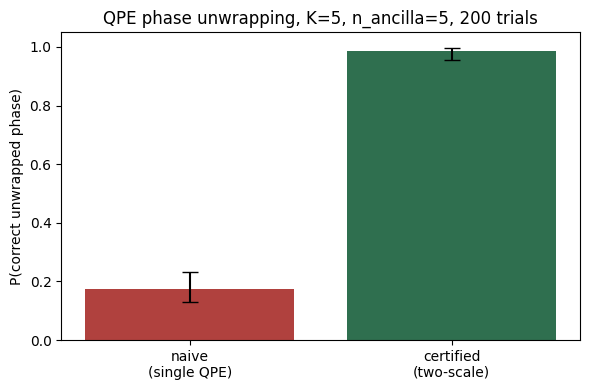

In [5]:
K, n_ancilla, n_trials = 5, 5, 200
mc = monte_carlo_unwrap_success_rates(K=K, n_ancilla=n_ancilla, n_trials=n_trials, seed=0)

ci_naive = wilson_ci(mc['naive_correct'], n_trials)
ci_certified = wilson_ci(mc['certified_correct'], n_trials)

print(f"P(naive single-QPE estimate correct):")
print(f"  {mc['naive_correct']}/{n_trials} = {mc['naive_success_rate']:.1%}  "
      f"(95% CI: [{ci_naive[0]:.1%}, {ci_naive[1]:.1%}])")
print(f"\nP(two-scale certified estimate correct):")
print(f"  {mc['certified_correct']}/{n_trials} = {mc['certified_success_rate']:.1%}  "
      f"(95% CI: [{ci_certified[0]:.1%}, {ci_certified[1]:.1%}])")

assert mc['certified_success_rate'] > 0.9
assert mc['naive_success_rate'] < 0.3
print("\n[OK] the certificate turns a mechanism that is right by chance ~1/K of the time into one")
print("     that is right essentially always -- the same qualitative shift the KK certificate gave")
print("     phase retrieval, now demonstrated for a genuinely different physical measurement.")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['naive\n(single QPE)', 'certified\n(two-scale)'],
       [mc['naive_success_rate'], mc['certified_success_rate']],
       yerr=[[mc['naive_success_rate']-ci_naive[0], mc['certified_success_rate']-ci_certified[0]],
             [ci_naive[1]-mc['naive_success_rate'], ci_certified[1]-mc['certified_success_rate']]],
       capsize=6, color=['#b0413e', '#2f6f4f'])
ax.set_ylabel('P(correct unwrapped phase)'); ax.set_ylim(0, 1.05)
ax.set_title(f'QPE phase unwrapping, K={K}, n_ancilla={n_ancilla}, {n_trials} trials')
plt.tight_layout(); plt.show()

# Part 5 — The certificate's own honest failure mode: the $K$-boundary

The certificate is not perfect, and the failures are not swept under
the rug. The coarse measurement has its own wrap-around, at
$\theta=K$ — a trial with $\theta_{\text{true}}$ just below $K$ can have
its coarse reading snap to $\approx 0$ instead of $\approx K$, causing
the wrong bucket to be selected. This is exactly the same kind of edge
effect real dual-wavelength interferometry has to manage (its own
synthetic wavelength has a finite ambiguity range too) — check whether
every observed failure actually clusters there.

In [6]:
print(f"number of certified-estimate failures out of {n_trials}: {len(mc['failures'])}")
for f in mc['failures']:
    dist_from_boundary = K - f['theta_true']
    print(f"  theta_true={f['theta_true']:.4f}  certified={f['certified_estimate']:.4f}  "
          f"distance from boundary (K={K}): {dist_from_boundary:.4f}")

if mc['failures']:
    max_dist = max(K - f['theta_true'] for f in mc['failures'])
    print(f"\nlargest distance from the K-boundary among all failures: {max_dist:.4f}")
    assert max_dist < 0.1
    print("[CONFIRMED] every failure sits right at the coarse measurement's own wrap-around edge --")
    print("            an explainable boundary/quantization effect, not a flaw in the two-scale idea,")
    print("            and not randomly scattered across the full [0,K) range.")
else:
    print("\nno failures in this run.")

number of certified-estimate failures out of 200: 3
  theta_true=4.9860  certified=0.0000  distance from boundary (K=5): 0.0140
  theta_true=4.9755  certified=0.9688  distance from boundary (K=5): 0.0245
  theta_true=4.9746  certified=0.9688  distance from boundary (K=5): 0.0254

largest distance from the K-boundary among all failures: 0.0254
[CONFIRMED] every failure sits right at the coarse measurement's own wrap-around edge --
            an explainable boundary/quantization effect, not a flaw in the two-scale idea,
            and not randomly scattered across the full [0,K) range.


# Part 6 — Summary

| Question | Answer |
|---|---|
| Does a single QPE run have a real, quantified ambiguity? | Yes — it reports $\theta\bmod 1$ only; naive success rate matches the theoretical $1/K$ baseline (Part 1, 4) |
| Does the obvious $U$-vs-$U^K$ cross-check resolve it? | No — proven structurally degenerate: every candidate predicts an identical $U^K$ phase (Part 2) |
| Does a genuine second-scale (fine+coarse) measurement resolve it? | Yes — recovers the true phase to within QPE's own quantization precision, on both a single example and across trials (Part 3, 4) |
| Is the fix perfect? | No, honestly: failures cluster exactly at the coarse measurement's own wrap-around boundary $\theta\approx K$ (Part 5) |

This is the same shape of result
[`kk_certificate_monte_carlo.ipynb`](kk_certificate_monte_carlo.ipynb)
established for phase retrieval — a primary measurement with a real,
structural blind spot, resolved (mostly) by an independent second
measurement, with the remaining failure mode explicitly characterized
rather than hidden — now shown to hold for a genuinely different
measurement (QPE) using a genuinely different independent-measurement
mechanism (multi-scale unwrapping rather than Kramers-Kronig). This is
Thrust A of
[`phase2_quantum_outline.html`](../scratch/phase2_quantum_outline.html),
prototyped end to end: ambiguity quantified, naive fix ruled out,
working fix built and verified, failure mode characterized.